# Aula 2 · Treinar e testar

**VERSÃO DO FACILITADOR: tudo resolvido, com notas.** Não copiar para os computadores dos alunos.

**12 minutos (12:05–12:17) · aula guiada, em pares** · a seguir: a Prática 2

**O que vamos fazer:** aprender a **avaliar** um modelo a sério. Separamos os exemplos em dois montes: um para **treinar** e outro para **testar**. Depois fazemos um grande exame com o mapa oficial da cheia e vemos que erros o modelo faz.

**Os dados:** a mesma imagem e os mesmos pontos da Aula 1, e `mapa_oficial_cheia_2026.npz` (o mapa oficial da cheia, para o exame).  
**Treino e teste:** **treino** = os primeiros 10 pontos de água e 10 de não água (498 píxeis); **teste** = os outros 5 + 5 (240 píxeis); **exame** = o mapa oficial (339 409 píxeis).  
**O algoritmo:** floresta aleatória com 100 árvores (classificação: água ou não água).

| Palavra nova | O que quer dizer |
| --- | --- |
| **treino** | os exemplos com que o modelo aprende |
| **teste** | exemplos guardados à parte, que o modelo nunca viu, para o avaliar |
| **acerto** | a parte das respostas certas (100 % = acertou tudo) |
| **floresta aleatória** | muitas árvores de decisão que votam (em inglês, Random Forest) |
| **matriz de confusão** | um quadro com os acertos e os dois tipos de erro |
| **falso alarme** | era terra e o modelo disse água |
| **água perdida** | era água e o modelo disse terra |

**Como trabalhar:** esta é a **aula guiada**: o facilitador mostra no projector e vocês acompanham.
Cliquem numa célula de código (as cinzentas) e carreguem em **Shift + Enter** para a correr, sempre **por ordem**, de
cima para baixo. A seguir vem a **prática**, em que são vocês a escrever o código. Guardem com **Ctrl + S**.

> **Nota para o facilitador.** Objectivo: a regra de ouro (nunca avaliar com o treino) e ler uma matriz de confusão. Tempo: 12 minutos, no projector. A seguir, a Prática 2, com outra separação dos pontos.

## Passo 1 · Abrir as ferramentas

In [1]:
import os, sys
for pasta in [".", os.path.join("..", "..", "2_pratica")]:          # a pasta onde está o ferramentas.py
    if os.path.exists(os.path.join(pasta, "ferramentas.py")):
        sys.path.insert(0, pasta)
        break
from ferramentas import *      # as ferramentas da aula
from sklearn.ensemble import RandomForestClassifier
print("Ferramentas prontas.")

Ferramentas prontas.


## Passo 2 · Separar os exemplos em treino e teste

A **regra de ouro**: nunca se avalia um modelo com os exemplos que ele usou para aprender. Seria como fazer um exame com as perguntas que já vimos resolvidas. Por isso separamos os pontos da equipa: **10 de água e 10 de não água para treinar**; os outros **5 + 5 ficam guardados para o teste**.

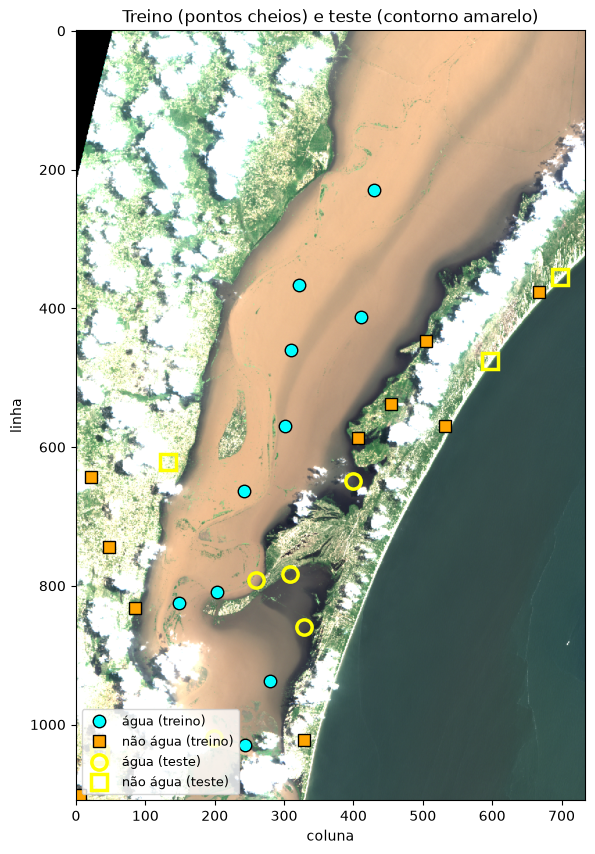

Exemplos de treino: 498    Exemplos de teste: 240


In [2]:
cheia = carregar("incomati_2026_cheia.npz")
pontos = pontos_da_equipa(2026)
agua_treino, agua_teste = pontos["agua"][:10], pontos["agua"][10:]
terra_treino, terra_teste = pontos["nao_agua"][:10], pontos["nao_agua"][10:]
ver_imagem(cheia, "Treino (pontos cheios) e teste (contorno amarelo)", agua_treino, terra_treino, agua_teste, terra_teste)
treino = tabela_de_exemplos(cheia, agua_treino, terra_treino)
teste = tabela_de_exemplos(cheia, agua_teste, terra_teste)
print("Exemplos de treino:", len(treino), "   Exemplos de teste:", len(teste))

> **Nota para o facilitador.** Resultado esperado: 498 exemplos de treino e 240 de teste. Os pontos de teste estão espalhados pela imagem, longe dos de treino.

## Passo 3 · Treinar uma floresta aleatória

Uma **floresta aleatória** são muitas árvores de decisão, cada uma treinada com uma parte diferente dos exemplos. Para cada píxel, as árvores **votam**: ganha a resposta com mais votos. Usamos 100 árvores, treinadas **só com o treino**.

In [3]:
floresta = RandomForestClassifier(n_estimators=100, random_state=0)   # 100 árvores
floresta.fit(treino[BANDAS], treino["rótulo"])                       # treinar só com o treino
print("Floresta treinada com", len(treino), "exemplos.")

Floresta treinada com 498 exemplos.


## Passo 4 · Duas notas: a do treino e a do teste

In [4]:
nota_treino = acerto(treino["rótulo"], floresta.predict(treino[BANDAS]))
nota_teste = acerto(teste["rótulo"], floresta.predict(teste[BANDAS]))
print("Acerto no TREINO (exemplos que já viu):", percentagem(nota_treino))
print("Acerto no TESTE (exemplos novos):      ", percentagem(nota_teste))

Acerto no TREINO (exemplos que já viu): 100,0 %
Acerto no TESTE (exemplos novos):       98,8 %


A nota do treino é quase sempre perfeita: o modelo já conhecia aquelas respostas. **A nota que conta é a do teste.**

> **Nota para o facilitador.** Resultado esperado: treino 100,0 %, teste 98,8 %. Pergunte: «qual das duas notas poríamos num relatório?»

## Passo 5 · O grande exame: o mapa oficial da cheia

O serviço europeu **Copernicus EMS** desenhou, a 24 de Janeiro de 2026, onde estava a água da cheia. São mais de 300 000 píxeis que o nosso modelo nunca viu: um exame muito maior e feito por outros.

In [5]:
verdade, previsto = exame_mapa_oficial(floresta, cheia)
print("Píxeis no exame:", numero(len(verdade)))
print("Acerto no exame:", percentagem(acerto(verdade, previsto)))

Píxeis no exame: 339 409
Acerto no exame: 98,2 %


## Passo 6 · A matriz de confusão: que erros fez?

O acerto diz quanto o modelo errou, mas não **como** errou. A **matriz de confusão** separa os dois tipos de erro: o **falso alarme** (era terra e disse água) e a **água perdida** (era água e disse terra).

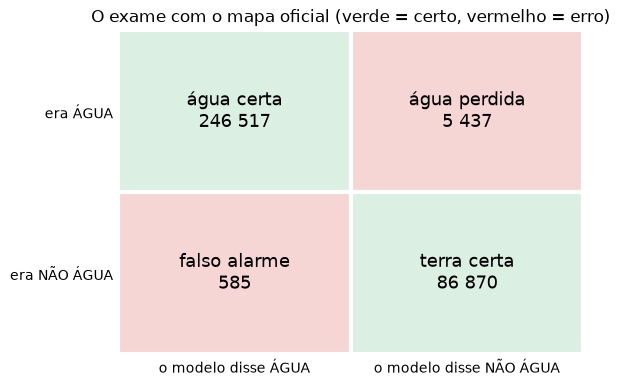

água certa       246 517 píxeis
água perdida       5 437 píxeis
falso alarme         585 píxeis
terra certa       86 870 píxeis


In [6]:
erros = matriz_de_confusao(verdade, previsto, "O exame com o mapa oficial")

> **Nota para o facilitador.** Resultado esperado: acerto 98,2 % em 339 409 píxeis; 585 falsos alarmes e 5 437 píxeis de água perdida. A maior parte da água perdida fica nas margens e na água com plantas ou muita lama. Pergunte qual dos erros é mais grave num aviso de cheias (a pergunta volta na Prática 2).

## O que aprendemos

- Separamos os exemplos: o **treino** para aprender e o **teste** para avaliar. Nunca se avalia com o treino.
- A nota do treino engana; a do **teste** diz a verdade.
- A **matriz de confusão** mostra os dois tipos de erro: o falso alarme e a água perdida.
- Uma **floresta aleatória** junta os votos de muitas árvores e erra menos do que uma só.
- Um modelo pode funcionar bem num ano e pior noutro: testa-se onde e quando vai ser usado.

## Guardar os modelos e as separações (só na versão do facilitador)

Ficam nas pastas `modelos_treinados/` e `separacoes/`, ao lado deste notebook. Para usar um modelo noutro notebook: `modelo = joblib.load("modelos_treinados/...joblib")`.

In [7]:
import joblib
os.makedirs("modelos_treinados", exist_ok=True)
os.makedirs("separacoes", exist_ok=True)
joblib.dump(floresta, "modelos_treinados/aula2_floresta_100_arvores.joblib")
pd.DataFrame([(l, c, 1) for l, c in agua_treino] + [(l, c, 0) for l, c in terra_treino],
             columns=["linha", "coluna", "rótulo"]).to_csv("separacoes/aula2_pontos_treino.csv", index=False)
pd.DataFrame([(l, c, 1) for l, c in agua_teste] + [(l, c, 0) for l, c in terra_teste],
             columns=["linha", "coluna", "rótulo"]).to_csv("separacoes/aula2_pontos_teste.csv", index=False)
treino.to_csv("separacoes/aula2_pixeis_treino.csv", index=False)
teste.to_csv("separacoes/aula2_pixeis_teste.csv", index=False)
print("Guardado em modelos_treinados/ e separacoes/.")

Guardado em modelos_treinados/ e separacoes/.


## Se aparecer um erro

Leiam a **última linha** da mensagem vermelha.

| A última linha diz | O que fazer |
| --- | --- |
| `NameError: name '...' is not defined` | Saltaram uma célula. Corram as células por ordem, a partir do Passo 1. |
| `FileNotFoundError: Não encontrei ...` | Abram o notebook a partir da pasta `Workshop_2/2_pratica`. |
| `ModuleNotFoundError` | Falta uma biblioteca neste computador: chamem um facilitador. |
| `NotFittedError` ou «O modelo ainda não foi treinado» | Falta treinar o modelo: corram a célula com `.fit(...)`. |
| `SyntaxError` | Falta uma aspa, um parêntese ou uma vírgula. Comparem com o exemplo. |
| «Falta preencher» | Troquem os `...` pela vossa resposta. |

Se nada resultar: menu **Kernel**, depois **Restart Kernel and Run All Cells**.